# Exploration — does adding the new surveys change the model?

Same estimator, same specification, same everything: the only change is **more rows**. The 2026-08
refresh brought surveys the fitted panel does not contain, and this asks whether adding them moves
the coefficients or the leave-one-country-out performance.

Nothing here is promoted. It writes to its own folder and touches no production artefact.

**Two things govern every number below.**

**1. The offline predictors now reach past 2022, but not to every survey year.** With
`params.OFFLINE_PREDICTORS_EDITION = 'latest'`, `hdi` and `gdi` reach 2023 and `gdp_pcap` reaches
2025. Under the project's year rule (exact year, else the latest earlier one — D32) **15 of the 17
added surveys take 2023 values and 2 take 2022** — printed below rather than asserted here. That is
much better than the uniform 2022 this notebook originally had to assume, but a 2024 or 2025 survey
still carries 2023 development indicators, so the added rows pair a contemporaneous Facebook signal
with an offline one that can be up to two years stale.

**2. The offline column is vintage-mixed at 2022.** Values at or below 2022 come from the shipped
extraction; values from 2023 come from the current UNDP/World Bank releases, and both sources revise
their back-series (D40). Section 5 measures what that seam is worth for `gdp_pcap`, the one variable
whose historical vintage can actually be re-pulled.


In [1]:
import sys
from pathlib import Path

# put src/ on the path — this notebook lives in src/analysis_notebooks/
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'params.py').exists())
sys.path.insert(0, str(SRC))

import json
from datetime import datetime
from glob import glob

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

import model_performance as mp
import params
import plotting as plot
plot.STYLE=dict(plot.STYLE); plot.STYLE["save"]=True
import utils

NOTEBOOK = '13_extended_panel_exploration'
CFG = params.FINAL_MODEL
SPEC = CFG['spec']
FB = ['fb_18_999_men', 'fb_18_999_wom', 'fb_18_999_r']
OFFLINE = ['hdi', 'gdi', 'gdp_pcap']

print('spec:', ' + '.join(SPEC))

spec: fb_18_999_men + fb_18_999_wom + fb_18_999_r + hdi + gdi + gdp_pcap + year


## 1. Build the extended panel

The new rows are assembled exactly the way the existing ones were, which had to be established
rather than assumed:

- **Facebook** — the panel's `fb_18_999_*` are the **yearly mean of the monthly series**. Checked
  against all 108 existing internet rows: median |difference| 0.0000. So the new rows take the
  same yearly mean.
- **Offline** — joined under `utils.join_latest_available_year`, which is the same rule the rest of
  the pipeline uses. `pred_year` records which year each row actually got.

In [2]:
def yearly_fb():
    """country-year Facebook ratios: the monthly series averaged within the year"""
    monthly = pd.read_csv(
        params.EXTERNAL / 'pipeline/preprocessed/national/fb_national_sd_rolling_std_202607.csv',
        usecols=['iso3', 'year', 'month'] + FB)
    return monthly.groupby(['iso3', 'year'], as_index=False)[FB].mean()


def offline_predictors():
    """
    the development indicators, complete cases only

    Reads `params.OFFLINE_PREDICTORS`, whose vintage is chosen once in params. With the edition set
    to 'latest' this is the shipped panel with the previously-empty later years filled in — hdi and
    gdi now reach 2023, gdp_pcap 2025 — so most added surveys get their own year rather than a
    carried one. No value at or before 2022 differs from the shipped file (D40).
    """
    frame = (pd.read_csv(params.OFFLINE_PREDICTORS, usecols=['iso3', 'year'] + OFFLINE)
             .dropna(subset=OFFLINE))
    # gdp_pcap is stored in raw current US$ (NY.GDP.PCAP.CD) but the fitted panel carries it
    # LOGGED: scripts/predictors.py:194 applies np.log when the panel is built, before continent
    # imputation. Without this line the added rows arrive ~200x the existing ones and the
    # gdp_pcap coefficient collapses to zero — the term is silently dropped from the model.
    frame['gdp_pcap'] = np.log(frame['gdp_pcap'])
    return frame


def load_groundtruth():
    matches = sorted(glob(str(params.EXTERNAL
                              / 'national/adolescent_modelling/update_full_groundtruth_*.csv')))
    return pd.read_csv(matches[-1])


def extend(indicator, groundtruth, fb, offline):
    """the fitted panel plus every survey it does not already contain"""
    panel = pd.read_csv(params.PROCESSED / 'combined_data/updated_ground_truth_and_fb'
                        / indicator / CFG['dataset'])
    panel['year'] = panel[f'{indicator}_year'] - CFG['year_origin']
    panel['source'] = 'existing'
    have = set(zip(panel['iso3'], panel[f'{indicator}_year'].astype(int)))

    new = groundtruth[['iso3', 'country', 'year', 'survey_type',
                       f'{indicator}_men', f'{indicator}_wom', f'{indicator}_fm_ratio']].copy()
    keep = ~pd.Series([(i, y) in have for i, y in zip(new['iso3'], new['year'])], index=new.index)
    new = new[keep].merge(fb, on=['iso3', 'year'], how='left')
    new = utils.join_latest_available_year(new, offline, key='iso3', year='year',
                                           used_year_col='pred_year')

    # the model needs the survey year on the panel's own column names
    new = new.rename(columns={f'{indicator}_fm_ratio': f'{indicator}_ggi',
                              'year': f'{indicator}_year'})
    new['year'] = new[f'{indicator}_year'] - CFG['year_origin']
    new['source'] = 'added'
    new = new.dropna(subset=FB + OFFLINE + [f'{indicator}_ggi'])

    # Guard the scale rather than trust it. A predictor that is logged on one set of rows and raw
    # on the other reads as a valid column and fails silently, so compare the two blocks directly.
    for col in OFFLINE:
        lo, hi = panel[col].median(), new[col].median()
        assert abs(np.log10(abs(hi / lo))) < 0.5, (
            f'{indicator}: {col} medians differ by {hi / lo:.0f}x between the existing rows '
            f'({lo:.3g}) and the added rows ({hi:.3g}) — the two blocks are on different scales')

    # dict.fromkeys de-duplicates while keeping order: 'year' is both a bookkeeping column here
    # and a term in SPEC, and selecting it twice gives the frame two identical 'year' columns,
    # which makes any later frame['year'] return a DataFrame instead of a Series.
    cols = list(dict.fromkeys(
        ['iso3', f'{indicator}_year', 'year', 'source'] + SPEC +
        [f'{indicator}_{o}' for o in CFG['outcome_vars']]))
    return panel[cols], pd.concat([panel[cols], new[cols]], ignore_index=True), new


groundtruth, fb, offline = load_groundtruth(), yearly_fb(), offline_predictors()
panels = {}
for indicator in CFG['indicators']:
    base, extended, added = extend(indicator, groundtruth, fb, offline)
    panels[indicator] = (base, extended)
    print(f'{indicator:9s} {len(base):4d} -> {len(extended):4d} rows  (+{len(added)})   '
          f'predictor year used: {added["pred_year"].value_counts().to_dict()}')

added[['iso3', 'country', f'{CFG["indicators"][-1]}_year', 'survey_type', 'pred_year']].reset_index(drop=True)

internet   108 ->  125 rows  (+17)   predictor year used: {2023: 15, 2022: 2}
mobile      99 ->  116 rows  (+17)   predictor year used: {2023: 15, 2022: 2}


,iso3,country,mobile_year,survey_type,pred_year
0,LSO,Lesotho,2022,dhs8,2022
1,MOZ,Mozambique,2022,dhs8,2022
2,AGO,Angola,2023,dhs8,2023
3,COD,Democratic Republic of the Congo,2023,dhs8,2023
4,ETH,Ethiopia,2024,dhs8,2023
5,JOR,Jordan,2023,dhs8,2023
6,MLI,Mali,2023,dhs8,2023
7,MWI,Malawi,2024,dhs8,2023
8,NGA,Nigeria,2024,dhs8,2023
9,RWA,Rwanda,2025,dhs8,2023


## 2. Refit and re-validate

`fit` and `loco` are the same functions the production audit uses (`src/model_performance.py`), so
the base numbers here must reproduce the ones in `02_model_performance.ipynb` — a useful check that
nothing has drifted.

In [3]:
rows, coef_rows = [], []

for indicator in CFG['indicators']:
    for label, data in zip(('base', 'extended'), panels[indicator]):
        for outcome_var in CFG['outcome_vars']:
            outcome = f'{indicator}_{outcome_var}'
            model = sm.OLS(data[outcome], sm.add_constant(data[SPEC]), missing='drop').fit()
            y, pred = mp.loco(data, SPEC, outcome, CFG['leave_column'])
            rows.append({'indicator': indicator, 'panel': label, 'outcome': outcome_var,
                         'n': int(model.nobs), 'r2': float(model.rsquared),
                         'loco_r2': float(mp.pooled_r2(y, pred)),
                         'loco_mae': float((y - pred).abs().mean())})
            for term, value in model.params.items():
                coef_rows.append({'indicator': indicator, 'panel': label,
                                  'outcome': outcome_var, 'term': term, 'coef': float(value)})

perf = pd.DataFrame(rows)
coefs = pd.DataFrame(coef_rows)

wide = perf.pivot_table(index=['indicator', 'outcome'], columns='panel',
                        values=['n', 'loco_r2', 'loco_mae'])
wide[('loco_r2', 'change')] = wide[('loco_r2', 'extended')] - wide[('loco_r2', 'base')]
wide.round(3)

loco_mae          loco_r2               n          loco_r2
panel                 base extended    base extended   base extended  change
indicator outcome                                                           
internet  ggi        0.084    0.087   0.791    0.766  108.0    125.0  -0.025
          men        0.082    0.086   0.843    0.819  108.0    125.0  -0.024
          wom        0.085    0.093   0.881    0.849  108.0    125.0  -0.032
mobile    ggi        0.065    0.068   0.683    0.670   99.0    116.0  -0.012
          men        0.076    0.074   0.563    0.571   99.0    116.0   0.009
          wom        0.083    0.086   0.749    0.735   99.0    116.0  -0.014

### Performance, before and after

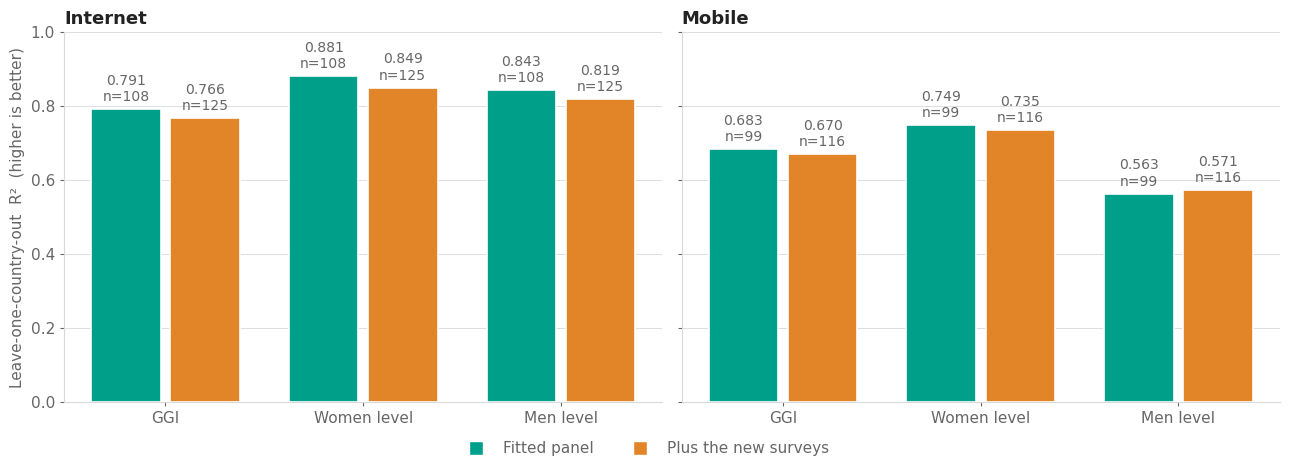

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)

colours = {'base': plot.PALETTE[0], 'extended': plot.PALETTE[1]}
outcomes = CFG['outcome_vars']
LABEL = {'ggi': 'GGI', 'wom': 'Women level', 'men': 'Men level'}

for ax, indicator in zip(axes, CFG['indicators']):
    block = perf[perf['indicator'] == indicator]
    values = {p: [float(block[(block['panel'] == p) & (block['outcome'] == o)]['loco_r2'].squeeze())
                  for o in outcomes] for p in ('base', 'extended')}
    counts = {p: [int(block[(block['panel'] == p) & (block['outcome'] == o)]['n'].squeeze())
                  for o in outcomes] for p in ('base', 'extended')}
    plot.grouped_bars(ax, [LABEL[o] for o in outcomes], ['base', 'extended'], values,
                      colours=colours, fmt='{:.3f}', counts=counts)
    plot.tidy(ax, title=indicator.capitalize(), grid='y')
    ax.set_ylim(0, 1.0)

axes[0].set_ylabel('Leave-one-country-out  R²  (higher is better)',
                   fontsize=plot.STYLE['tick_fs'], color=plot.MUTED)
plot.legend(fig, [plot.swatch(colours['base'], 'Fitted panel'),
                  plot.swatch(colours['extended'], 'Plus the new surveys')], y=-0.06)
#plot.suptitle(fig, 'Does adding the new surveys improve out-of-sample fit?')
fig.tight_layout(rect=(0, 0, 1, 0.93))
plot.save(fig, NOTEBOOK, 'loco_r2_base_vs_extended')
plt.show()

## 3. Do the coefficients move?

Adding 17 rows to ~100 should not overturn a coefficient. If one does, the added rows are pulling
against the existing sample rather than reinforcing it, and that is worth knowing before anyone
proposes adopting them.

In [5]:
pivot = coefs.pivot_table(index=['indicator', 'outcome', 'term'], columns='panel', values='coef')
pivot['change'] = pivot['extended'] - pivot['base']
pivot['pct_change'] = 100 * pivot['change'] / pivot['base'].abs().replace(0, np.nan)
pivot['sign_flip'] = np.sign(pivot['base']) != np.sign(pivot['extended'])

print('coefficients that change sign:', int(pivot['sign_flip'].sum()))
pivot.reindex(columns=['base', 'extended', 'change', 'pct_change', 'sign_flip']).round(4)

coefficients that change sign: 1


panel                              base  extended  change  pct_change  \
indicator outcome term                                                  
internet  ggi     const         -1.2246   -1.1671  0.0575      4.6976   
                  fb_18_999_men  0.7752    0.7905  0.0152      1.9636   
                  fb_18_999_r    0.5062    0.5315  0.0253      4.9913   
                  fb_18_999_wom -0.7305   -0.7402 -0.0097     -1.3291   
                  gdi            1.3733    1.3215 -0.0518     -3.7695   
                  gdp_pcap       0.0049    0.0057  0.0009     17.8137   
                  hdi            0.2592    0.1993 -0.0599    -23.1235   
                  year           0.0092    0.0097  0.0005      5.7847   
          men     const         -0.9995   -0.9987  0.0007      0.0728   
                  fb_18_999_men  0.7222    0.7702  0.0480      6.6484   
                  fb_18_999_r    0.1083    0.1390  0.0307     28.3166   
                  fb_18_999_wom -0.5684   -0.5952 -0.0267     -4.7002   
                  gdi            0.5241    0.4690 -0.0551    -10.5189   
                  gdp_pcap       0.0423    0.0620  0.0197     46.5802   
                  hdi            0.7192    0.5267 -0.1925    -26.7642   
                  year           0.0190    0.0145 -0.0046    -23.9666   
          wom     const         -1.6224   -1.6231 -0.0007     -0.0429   
                  fb_18_999_men  0.5261    0.5789  0.0529     10.0525   
                  fb_18_999_r    0.1226    0.1736  0.0510     41.6193   
                  fb_18_999_wom -0.3511   -0.3848 -0.0337     -9.6011   
                  gdi            1.0564    1.0148 -0.0416     -3.9368   
                  gdp_pcap       0.0355    0.0515  0.0159     44.8484   
                  hdi            0.8636    0.6846 -0.1790    -20.7240   
                  year           0.0198    0.0141 -0.0056    -28.5611   
mobile    ggi     const         -0.4306   -0.3134  0.1173     27.2304   
                  fb_18_999_men  0.4765    0.5206  0.0441      9.2588   
                  fb_18_999_r    0.2975    0.3323  0.0348     11.6876   
                  fb_18_999_wom -0.4370   -0.4775 -0.0405     -9.2774   
                  gdi            0.9553    0.8186 -0.1367    -14.3114   
                  gdp_pcap       0.0123    0.0041 -0.0081    -66.3161   
                  hdi            0.0487    0.1339  0.0852    174.9716   
                  year           0.0043    0.0008 -0.0034    -80.2882   
          men     const          0.3205    0.2590 -0.0615    -19.1868   
                  fb_18_999_men  0.7827    0.8110  0.0283      3.6149   
                  fb_18_999_r    0.1746    0.1849  0.0103      5.8776   
                  fb_18_999_wom -0.7720   -0.7942 -0.0222     -2.8755   
                  gdi           -0.3954   -0.3385  0.0569     14.3923   
                  gdp_pcap       0.0782    0.0875  0.0093     11.9062   
                  hdi            0.0244   -0.0880 -0.1124   -460.6888   
                  year           0.0047    0.0027 -0.0020    -43.2437   
          wom     const         -0.8632   -0.7767  0.0865     10.0211   
                  fb_18_999_men  0.9328    0.9860  0.0532      5.7019   
                  fb_18_999_r    0.3301    0.3657  0.0356     10.7881   
                  fb_18_999_wom -0.8934   -0.9351 -0.0417     -4.6621   
                  gdi            0.6194    0.5114 -0.1080    -17.4317   
                  gdp_pcap       0.0780    0.0758 -0.0022     -2.7941   
                  hdi            0.0346    0.0492  0.0146     42.3457   
                  year           0.0069    0.0026 -0.0042    -61.8619   

panel                            sign_flip  
indicator outcome term                      
internet  ggi     const              False  
                  fb_18_999_men      False  
                  fb_18_999_r        False  
                  fb_18_999_wom      False  
                  gdi                False  
                  gdp_pcap        

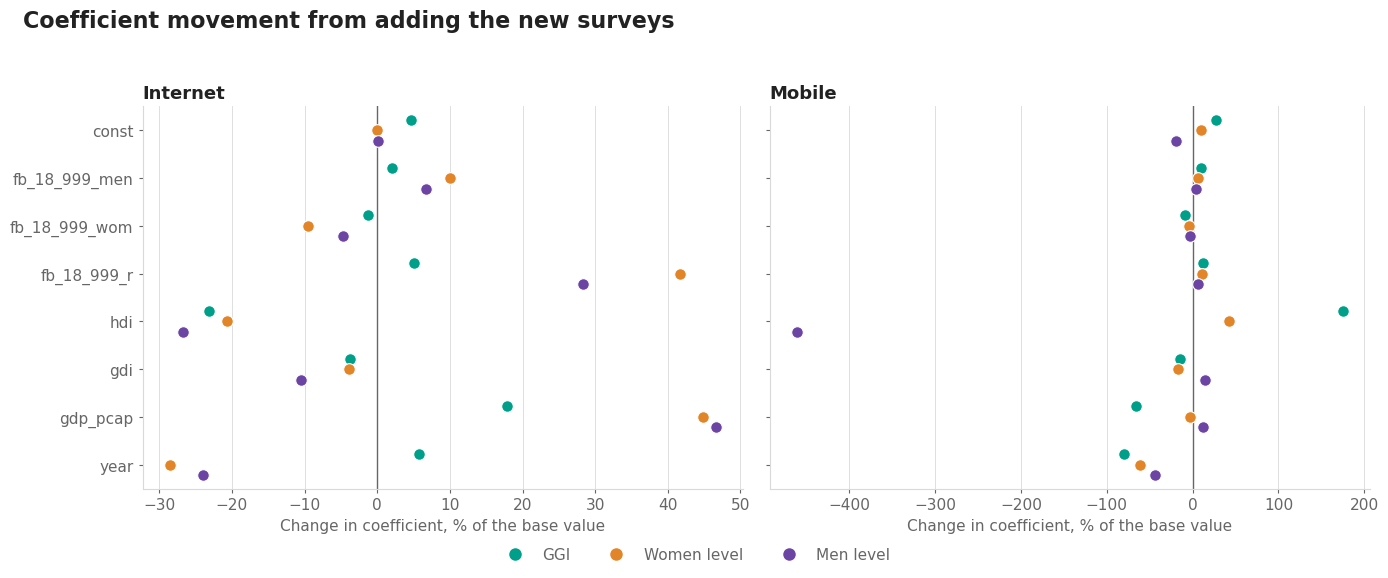

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

terms = [t for t in ['const'] + SPEC]
for ax, indicator in zip(axes, CFG['indicators']):
    block = pivot.loc[indicator].reset_index()
    for k, outcome in enumerate(outcomes):
        sub = block[block['outcome'] == outcome].set_index('term').reindex(terms)
        # relative movement, so terms on wildly different scales are comparable
        ax.scatter(sub['pct_change'], np.arange(len(terms)) + (k - 1) * 0.22,
                   s=70, color=plot.PALETTE[k], edgecolor='white', linewidth=0.8, zorder=3)
    ax.axvline(0, color=plot.MUTED, linewidth=1)
    ax.set_yticks(np.arange(len(terms)))
    ax.set_yticklabels(terms)
    ax.set_ylim(len(terms) - 0.5, -0.5)
    plot.tidy(ax, title=indicator.capitalize(),
              xlabel='Change in coefficient, % of the base value', grid='x')

plot.legend(fig, [plot.swatch(plot.PALETTE[k], LABEL[o], marker='o')
                  for k, o in enumerate(outcomes)], y=-0.05)
plot.suptitle(fig, 'Coefficient movement from adding the new surveys')
fig.tight_layout(rect=(0, 0, 1, 0.94))
plot.save(fig, NOTEBOOK, 'coefficient_movement')
plt.show()

## 4. Do the new surveys fit better once the model is refitted on them?

Sections 2 and 3 ask what the added rows do to the model. This asks the reverse: **what the refitted
model does for the added rows.** If adding 17 country-years is worth anything, the most direct place
to see it is on those 17.

**The comparison has to be blinded, or it is not a comparison.** The extended panel *contains* the
added rows, so an in-sample prediction for one is partly a prediction of itself, and would beat the
production model by construction. Every number here is therefore country-blind:

| arm | fitted on | predicting |
| --- | --- | --- |
| `production` | the fitted panel | the added rows — out of sample because they are not in it |
| `production_loco` | the fitted panel **minus that country** | the added rows |
| `extended` | the extended panel **minus that country** | every row, added and existing |

`production_loco` is the like-for-like comparator. Without it the production model would quietly be
allowed the 13 repeat countries it has already seen (D42) while the extended model is not. The
plain `production` arm is kept alongside because it is the model as it actually stands, and it is
the quantity `03_unseen_survey_validation.ipynb` reports.

The existing rows are carried through the same `mp.loco` call, so the fitted cloud on the figure is
the extended model's own out-of-sample performance on the panel it was fitted on — the reference
the new surveys are read against.

In [7]:
COUNTRY = groundtruth.dropna(subset=['country']).drop_duplicates('iso3').set_index('iso3')['country']


def predict_holding_out_country(train, test, outcome, spec=SPEC, leave=CFG['leave_column']):
    """
    fit on `train` with each test row's country removed, then predict that row

    The added rows are out of sample under the base panel either way — they are not in it. Holding
    the country out as well is what makes the arms comparable: the extended panel CONTAINS the
    added rows, so its prediction for one is only readable against a base-panel prediction that is
    blind to the same country. Without this the base model is quietly allowed the 13 countries it
    has already seen (D42) while the extended model is not.
    """
    est = train.dropna(subset=list(spec) + [outcome])
    preds = pd.Series(index=test.index, dtype=float)
    for held, rows in test.groupby(leave):
        fit_on = est[est[leave] != held]
        reg = sm.OLS(fit_on[outcome], sm.add_constant(fit_on[spec])).fit()
        preds.loc[rows.index] = reg.predict(sm.add_constant(rows[spec], has_constant='add'))
    return preds


pred_rows = []
for indicator in CFG['indicators']:
    base, extended = panels[indicator]
    added = extended[extended['source'] == 'added']

    for outcome_var in CFG['outcome_vars']:
        outcome = f'{indicator}_{outcome_var}'

        def record(frame, arm, pred):
            pred_rows.append(pd.DataFrame({
                'indicator': indicator, 'outcome': outcome_var, 'arm': arm,
                'iso3': frame['iso3'].values,
                'survey_year': frame[f'{indicator}_year'].astype(int).values,
                'source': frame['source'].values,
                'truth': frame[outcome].values, 'pred': np.asarray(pred)}))

        # 1. the extended model, scored exactly as everything else in this notebook is scored: no
        #    prediction comes from a model that saw the country. Covers the existing rows too,
        #    which is what puts the fitted cloud on the chart behind the new surveys.
        y, pred = mp.loco(extended, SPEC, outcome, CFG['leave_column'])
        record(extended.loc[y.index], 'extended', pred)

        # 2. the production model as it stands. Refitting rather than loading the shipped pickle is
        #    safe: D37 matched every pickle against a refit to ~1e-15.
        est = base.dropna(subset=SPEC + [outcome])
        reg = sm.OLS(est[outcome], sm.add_constant(est[SPEC])).fit()
        record(added, 'production', reg.predict(sm.add_constant(added[SPEC], has_constant='add')))

        # 3. the same model blinded to the country — the like-for-like comparator for arm 1
        record(added, 'production_loco', predict_holding_out_country(base, added, outcome))

preds_long = pd.concat(pred_rows, ignore_index=True)

# The published series bounds a predicted LEVEL to [0, 1] — it is a share — and the direct GGI is
# left unbounded, since a ratio above parity is meaningful (D19). A raw OLS prediction respects
# neither, so apply the same bound here or these numbers are not the model's actual output. It
# touches 4 of 68 level rows, all Qatar 2023, and moves no comparison by more than 0.001; it is
# here for fidelity, not for the result.
level = preds_long['outcome'].isin(['wom', 'men'])
preds_long['pred'] = preds_long['pred'].where(~level, preds_long['pred'].clip(0, 1))
preds_long['error'] = preds_long['pred'] - preds_long['truth']
preds_long['country'] = preds_long['iso3'].map(COUNTRY)

# only the extended arm carries existing rows; the other two are defined on the added rows alone
assert (preds_long[preds_long['arm'] != 'extended']['source'] == 'added').all()

added_acc = (preds_long[preds_long['source'] == 'added']
             .groupby(['indicator', 'outcome', 'arm'], as_index=False)
             .agg(n=('truth', 'size'), mae=('error', lambda e: e.abs().mean()),
                  bias=('error', 'mean'))
             .pivot_table(index=['indicator', 'outcome'], columns='arm', values=['mae', 'bias']))
added_acc[('mae', 'change')] = (added_acc[('mae', 'extended')]
                                - added_acc[('mae', 'production_loco')])
print(added_acc.round(4).to_string())
print('\nnegative `change` = the refitted model is closer to the new surveys than the production '
      'model is, both blinded to the country\n')

# an average can hide a mix, so count the surveys that actually moved each way
duel = (preds_long[preds_long['source'] == 'added']
        .query('arm != "production"')
        .pivot_table(index=['indicator', 'outcome', 'iso3', 'survey_year'],
                     columns='arm', values='error', aggfunc=lambda e: e.abs().iloc[0]))
duel['closer'] = duel['extended'] < duel['production_loco']
print(duel.groupby(['indicator', 'outcome'])['closer']
      .agg(refit_closer='sum', of='size').to_string())

                      bias                                 mae                                   
arm               extended production production_loco extended production production_loco  change
indicator outcome                                                                                
internet  ggi      -0.0066    -0.0099         -0.0118   0.1105     0.0976          0.1026  0.0079
          men       0.0049     0.0247          0.0240   0.1231     0.1244          0.1286 -0.0055
          wom       0.0067     0.0313          0.0301   0.1483     0.1469          0.1522 -0.0039
mobile    ggi       0.0148     0.0343          0.0330   0.0829     0.0816          0.0841 -0.0012
          men       0.0075     0.0175          0.0171   0.0612     0.0571          0.0604  0.0007
          wom       0.0119     0.0343          0.0328   0.0980     0.0929          0.0968  0.0011

negative `change` = the refitted model is closer to the new surveys than the production model is, both blinded to the

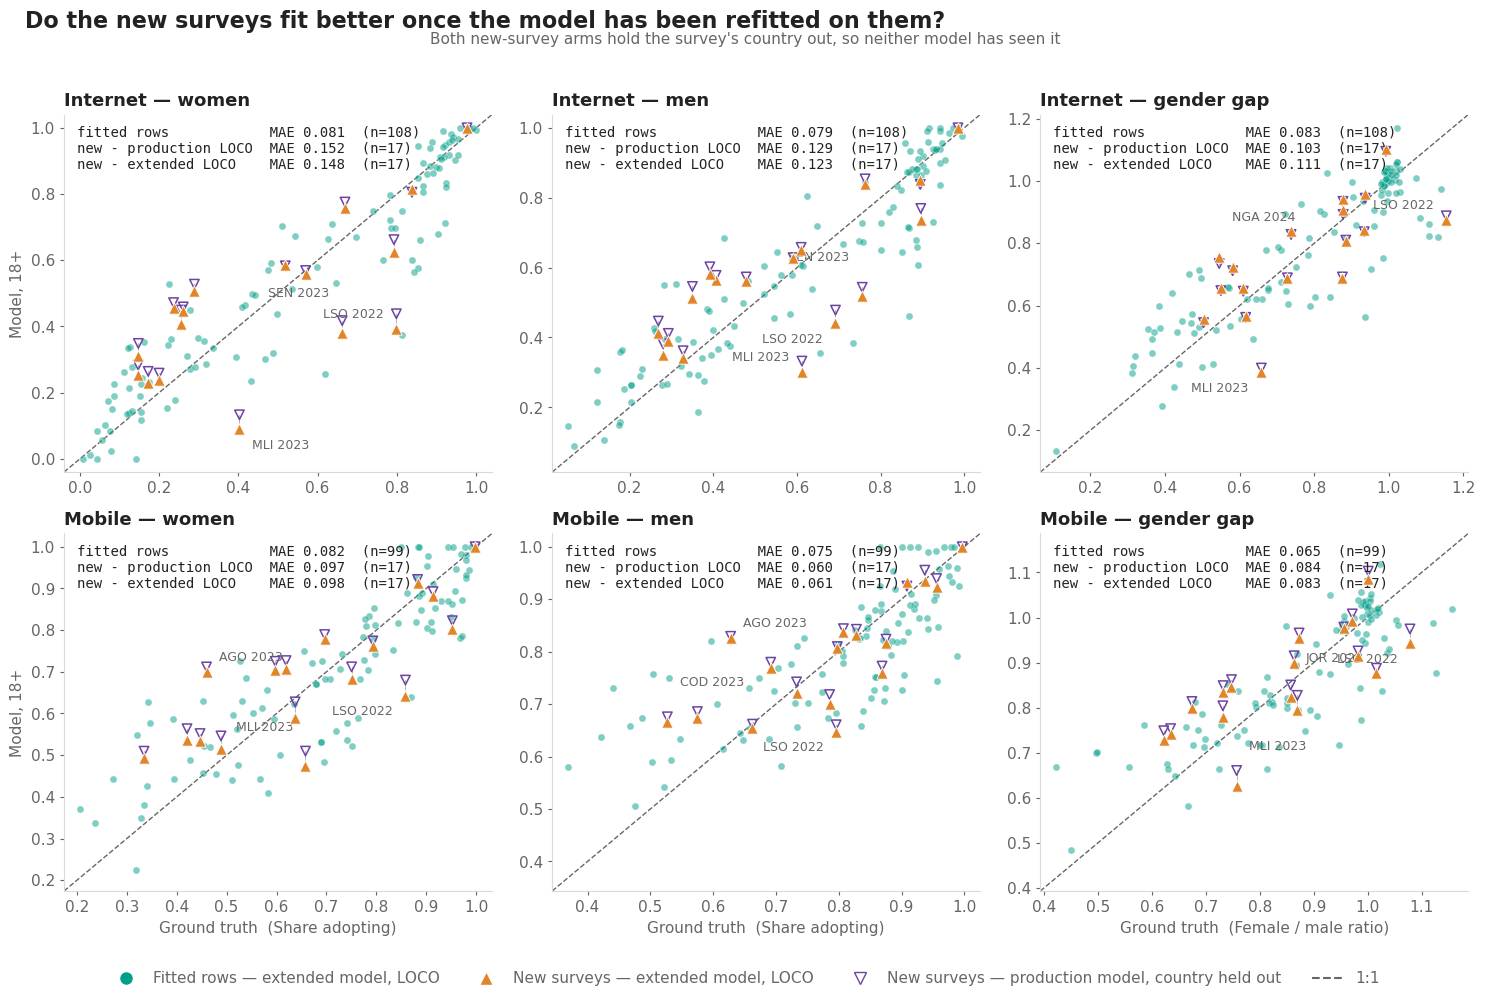

In [8]:
DISPLAY = ['wom', 'men', 'ggi']                      # levels first, then the ratio built from them
TITLE = {'wom': 'women', 'men': 'men', 'ggi': 'gender gap'}
AXIS = {'wom': 'Share adopting', 'men': 'Share adopting', 'ggi': 'Female / male ratio'}
EXISTING, ADDED, PROD = plot.PALETTE[0], plot.PALETTE[1], plot.PALETTE[2]

fig, axes = plt.subplots(2, 3, figsize=(15, 9.8))

for row, indicator in enumerate(CFG['indicators']):
    for col, outcome_var in enumerate(DISPLAY):
        ax = axes[row, col]
        block = preds_long[(preds_long['indicator'] == indicator)
                           & (preds_long['outcome'] == outcome_var)]
        ext = block[block['arm'] == 'extended']
        fitted, new = ext[ext['source'] == 'existing'], ext[ext['source'] == 'added']
        prod = block[block['arm'] == 'production_loco']

        lo = min(block['truth'].min(), block['pred'].min())
        hi = max(block['truth'].max(), block['pred'].max())
        pad = 0.04 * (hi - lo)
        ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], linestyle='--', linewidth=1,
                color=plot.MUTED, zorder=1)

        ax.scatter(fitted['truth'], fitted['pred'], s=26, color=EXISTING, alpha=0.5,
                   edgecolor='white', linewidth=0.4, zorder=2)
        # the same survey under both models, joined, so the pair reads as a pair rather than as
        # two unrelated clouds
        ax.scatter(prod['truth'], prod['pred'], s=46, marker='v', facecolor='none',
                   edgecolor=PROD, linewidth=1.1, zorder=3)
        for (_, a), (_, b) in zip(prod.iterrows(), new.iterrows()):
            ax.plot([a['truth'], b['truth']], [a['pred'], b['pred']], color=plot.MUTED,
                    linewidth=0.6, alpha=0.55, zorder=2)
        ax.scatter(new['truth'], new['pred'], s=66, marker='^', color=ADDED,
                   edgecolor='white', linewidth=0.6, zorder=4)

        # the three worst added surveys under the refitted model, named. Labels flip to the inside
        # of the panel near an edge and stagger vertically, so they cannot collide.
        worst = new.reindex(new['error'].abs().sort_values(ascending=False).index).head(3)
        mid = 0.5 * (lo + hi)
        for k, (_, r) in enumerate(worst.iterrows()):
            right = r['truth'] < mid
            ax.annotate(f'{r["iso3"]} {r["survey_year"]}', (r['truth'], r['pred']),
                        textcoords='offset points',
                        xytext=(9 if right else -9, [8, -14, 26][k]),
                        ha='left' if right else 'right',
                        fontsize=plot.STYLE['tick_fs'] - 2, color=plot.MUTED)

        mae = lambda f: f['error'].abs().mean()
        ax.text(0.03, 0.97,
                f'fitted rows            MAE {mae(fitted):.3f}  (n={len(fitted)})\n'
                f'new - production LOCO  MAE {mae(prod):.3f}  (n={len(prod)})\n'
                f'new - extended LOCO    MAE {mae(new):.3f}  (n={len(new)})',
                transform=ax.transAxes, va='top', ha='left', family='monospace',
                fontsize=plot.STYLE['tick_fs'] - 1, color=plot.INK)

        plot.tidy(ax, title=f'{indicator.capitalize()} — {TITLE[outcome_var]}',
                  xlabel=f'Ground truth  ({AXIS[outcome_var]})' if row else None,
                  ylabel='Model, 18+' if col == 0 else None)
        ax.set_xlim(lo - pad, hi + pad)
        ax.set_ylim(lo - pad, hi + pad)

plot.legend(fig, [
    plot.swatch(EXISTING, 'Fitted rows — extended model, LOCO', marker='o'),
    plot.swatch(ADDED, 'New surveys — extended model, LOCO', marker='^'),
    plt.Line2D([], [], marker='v', linestyle='None', markersize=9, markerfacecolor='none',
               markeredgecolor=PROD, label='New surveys — production model, country held out'),
    plt.Line2D([], [], linestyle='--', color=plot.MUTED, label='1:1')], y=-0.03)
plot.suptitle(fig, 'Do the new surveys fit better once the model has been refitted on them?')
fig.text(0.5, 0.945, "Both new-survey arms hold the survey's country out, so neither model has "
                     'seen it', ha='center', fontsize=plot.STYLE['tick_fs'], color=plot.MUTED)
fig.tight_layout(rect=(0, 0.02, 1, 0.95))
plot.save(fig, NOTEBOOK, '4_extended_vs_groundtruth')
plt.show()

### What the comparison says

**Refitting on the new surveys does almost nothing for the new surveys.** The change in MAE runs
from −0.006 to +0.008 across the six targets — smaller than the difference between the two
indicators, and far smaller than the gap between the fitted rows and the added ones:

| MAE on the 17 added surveys | internet ggi | internet wom | internet men | mobile ggi | mobile wom | mobile men |
| --- | --- | --- | --- | --- | --- | --- |
| production, country held out | 0.103 | 0.152 | 0.129 | 0.084 | 0.097 | 0.060 |
| extended, LOCO | 0.111 | 0.148 | 0.123 | 0.083 | 0.098 | 0.061 |
| change | **+0.008** | −0.004 | −0.006 | −0.001 | +0.001 | +0.001 |

The per-survey counts say the same thing in a form an average cannot hide: the refitted model is
closer on 3 to 12 of the 17 surveys depending on the target — a coin flip, not a shift. The one
visible movement is the internet GGI going the *wrong* way, which is the target the extended panel
was supposed to help most.

**Why this is the expected result rather than a disappointing one.** Seventeen rows against 108
cannot move a seven-term OLS far, and D42 established what the error on these surveys actually is:
a **persistent per-country level offset**, the same size at years the model was fitted on as at
years it was not. Adding one more year for a country whose level the model is already 0.24 low on
does not correct the offset — it fits a regression line through it. Mali, Lesotho and Senegal are
the three largest misses under *both* models, and they are the same countries D42 names.

**Read together with §2**, the picture is consistent: adding the surveys costs a little LOCO R² on
the panel as a whole (−0.018 internet GGI, −0.009 mobile) and buys nothing on the surveys
themselves. The case for the extended panel does not rest on accuracy — it rests on coverage, and
on whether a level offset gets absorbed by a term the specification does not currently carry.

The `bias` columns are the other half of the finding. On the added surveys both models sit **above**
the observation on every target (bias +0.01 to +0.03), and refitting *reduces* that bias on all
six — internet women from +0.030 to +0.007, mobile women from +0.033 to +0.012. So the added rows
do pull the model toward themselves in level; it is just that a smaller mean error and an unchanged
absolute error together say the movement is a shift, not a tightening.

#### These are not the MAEs in `03_unseen_survey_validation`, and they should not be

`03` reports **0.140** for internet women on the same 17 surveys; the production arm here reports
0.147, and the country-held-out arm 0.152. The rows are identical — merged survey by survey, the
ground truth agrees to **exactly 0.0** on all 17 — so the whole difference is in the *prediction*,
and it has three separable parts:

1. **The figure's box quotes the country-held-out arm**, not the production model as it stands.
   That is deliberate (it is the only arm comparable to the extended one) but it is the larger
   number: 0.152 against 0.147.
2. **Different prediction object.** `03` scores the **published national series** — what the
   shipped pipeline actually emitted for that country-year, read through
   `04_coherent_ggi_figures`' country-year table. This section scores a **refit of the base panel**
   applied to predictors assembled in §1: the yearly mean of the monthly Facebook series, and
   `hdi`/`gdi`/`gdp_pcap` at the refreshed vintage. Same specification, same estimator, a different
   design matrix — median per-survey difference **0.018**, maximum 0.076 (Nauru).
3. **Bounding.** The published series clips a predicted level to [0, 1]; a raw OLS fit does not.
   This section now applies the same bound, which is worth 0.004 on internet women (0.151 → 0.147)
   and comes almost entirely from Qatar 2023, predicted at 1.065.

| internet women, 17 surveys | MAE |
| --- | --- |
| `03`, published series | **0.140** |
| here, production refit, bounded | 0.147 |
| here, production refit, country held out | **0.152** |

**Neither is wrong; they answer different questions.** `03` asks how the *shipped model* did on data
it never saw. This section asks whether *refitting* would have done better, which requires both
sides to be refits on the same predictor assembly — the comparison is internally consistent, and
that is what makes the `change` column meaningful even though the levels do not match `03`.

## 5. Does the `gdp_pcap` vintage matter?

`gdp_pcap` is the least stable predictor in the spec. It is World Bank `NY.GDP.PCAP.CD` — GDP per
capita in **current US$**, so it carries exchange-rate movement and inflation as well as real
output, and the World Bank revises its whole back-series with each release while serving only the
current vintage through the API.

The panel above is therefore **vintage-mixed, with a seam at 2022**. `05_offline_predictors_update.py`
was written to never overwrite an existing cell (D40, and the instruction that produced it), so:

- **rows ≤ 2022** carry the World Bank vintage that was current when the shipped file was built;
- **rows ≥ 2023** — which is where the added surveys live — carry today's API vintage.

A 2019 GDP per capita and a 2024 one are consequently not on the same basis. This section replaces
`gdp_pcap` on *every* row with the current vintage, so the column is one vintage throughout, and
refits. Four arms: {base panel, extended panel} × {shipped mix, current vintage throughout}.

Only `gdp_pcap` is re-sourced. `hdi` and `gdi` have the same seam and the same problem, but the HDR
back-series is not retrievable per-vintage from the API, so they cannot be treated the same way —
`06_offline_predictors_build.py` is the route for those, at the price of changing history.


In [9]:
def current_wdi_gdp_pcap():
    """
    log GDP per capita, current World Bank vintage, for every country-year the API serves

    Read from the cache that `05_offline_predictors_update.py` already populated so this notebook
    does not re-hit the API; downloaded on a cache miss. Logged here, matching the panel's own
    treatment (scripts/predictors.py:194).
    """
    cache = params.PROCESSED / 'offline_predictors_cache' / 'wb_NY.GDP.PCAP.CD_src2.json'
    if not cache.exists():
        import urllib.request
        url = ('https://api.worldbank.org/v2/country/all/indicator/NY.GDP.PCAP.CD'
               f'?format=json&per_page=25000&date=1960:{datetime.now().year}&source=2')
        cache.parent.mkdir(parents=True, exist_ok=True)
        req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req, timeout=180) as r:
            cache.write_bytes(r.read())

    payload = json.load(open(cache))
    frame = pd.DataFrame([{'iso3': r['countryiso3code'], 'year': int(r['date']),
                           'gdp_pcap': r['value']}
                          for r in payload[1] if r['countryiso3code']]).dropna()
    frame['gdp_pcap'] = np.log(frame['gdp_pcap'])
    return frame.sort_values(['iso3', 'year'], ignore_index=True)


wdi = current_wdi_gdp_pcap()
print(f'current WDI vintage: {len(wdi)} country-years, {wdi["iso3"].nunique()} countries, '
      f'{wdi["year"].min()}-{wdi["year"].max()}')

# Where the seam is, measured. The shipped file and the API are the same series from two vintages,
# so any disagreement is revision, not a different quantity.
shipped = pd.read_csv(params.OFFLINE_PREDICTORS, usecols=['iso3', 'year', 'gdp_pcap']).dropna()
seam = shipped.merge(wdi.assign(now=np.exp(wdi['gdp_pcap']))[['iso3', 'year', 'now']],
                     on=['iso3', 'year'])
seam['rel'] = ((seam['now'] - seam['gdp_pcap']) / seam['gdp_pcap']).abs()

print(f'\nshipped offline_predictors vs current API, {len(seam)} overlapping country-years')
print(f'{"period":12s} {"n":>6s} {"identical":>10s} {"median revision":>16s}')
for lo, hi in [(1990, 1999), (2000, 2009), (2010, 2019), (2020, 2022), (2023, 2025)]:
    b = seam[seam['year'].between(lo, hi)]
    if len(b):
        print(f'{lo}-{hi:<7d} {len(b):6d} {100 * (b["rel"] < 1e-9).mean():9.1f}% '
              f'{b["rel"].median():15.4f}')
print('\n2023-2025 is 100% identical because those cells WERE this API pull — that is the seam.')


current WDI vintage: 14481 country-years, 257 countries, 1960-2025

shipped offline_predictors vs current API, 11214 overlapping country-years
period            n  identical  median revision
1990-1999      1879       9.7%          0.0077
2000-2009      2064       8.1%          0.0077
2010-2019      2114       3.6%          0.0108
2020-2022       613       1.0%          0.0205
2023-2025       719     100.0%          0.0000

2023-2025 is 100% identical because those cells WERE this API pull — that is the seam.


In [10]:
def revintage(frame, indicator):
    """swap gdp_pcap for the current vintage, on the survey year, same exact-else-latest rule"""
    out = frame.drop(columns=['gdp_pcap']).copy()
    out['_centred'] = out['year']                       # year is centred on 2015 in the spec
    out['year'] = out[f'{indicator}_year'].astype(int)  # join on the real survey year
    out = utils.join_latest_available_year(out, wdi, key='iso3', year='year',
                                           used_year_col='wdi_year')
    out['year'] = out['_centred']
    return out.drop(columns='_centred')


vintage_rows = []
for indicator in CFG['indicators']:
    for panel_name, data in zip(('base', 'extended'), panels[indicator]):
        for vintage, frame in [('shipped mix', data), ('current throughout', revintage(data, indicator))]:
            frame = frame.dropna(subset=SPEC)
            for outcome_var in CFG['outcome_vars']:
                outcome = f'{indicator}_{outcome_var}'
                model = sm.OLS(frame[outcome], sm.add_constant(frame[SPEC]), missing='drop').fit()
                y, pred = mp.loco(frame, SPEC, outcome, CFG['leave_column'])
                vintage_rows.append({
                    'indicator': indicator, 'panel': panel_name, 'vintage': vintage,
                    'outcome': outcome_var, 'n': int(model.nobs),
                    'loco_r2': float(mp.pooled_r2(y, pred)),
                    'loco_mae': float((y - pred).abs().mean()),
                    'beta_gdp_pcap': float(model.params['gdp_pcap'])})

vintages = pd.DataFrame(vintage_rows)
assert (vintages.groupby(['indicator', 'panel'])['n'].nunique() == 1).all(), \
    're-sourcing dropped rows — the two vintages must be compared on the same sample'

vintages.pivot_table(index=['indicator', 'outcome'], columns=['panel', 'vintage'],
                     values='loco_r2').round(3)


panel                           base                       extended  \
vintage           current throughout shipped mix current throughout   
indicator outcome                                                     
internet  ggi                  0.792       0.791              0.768   
          men                  0.844       0.843              0.822   
          wom                  0.882       0.881              0.852   
mobile    ggi                  0.683       0.683              0.671   
          men                  0.558       0.563              0.569   
          wom                  0.748       0.749              0.738   

panel                          
vintage           shipped mix  
indicator outcome              
internet  ggi           0.766  
          men           0.819  
          wom           0.849  
mobile    ggi           0.670  
          men           0.571  
          wom           0.735

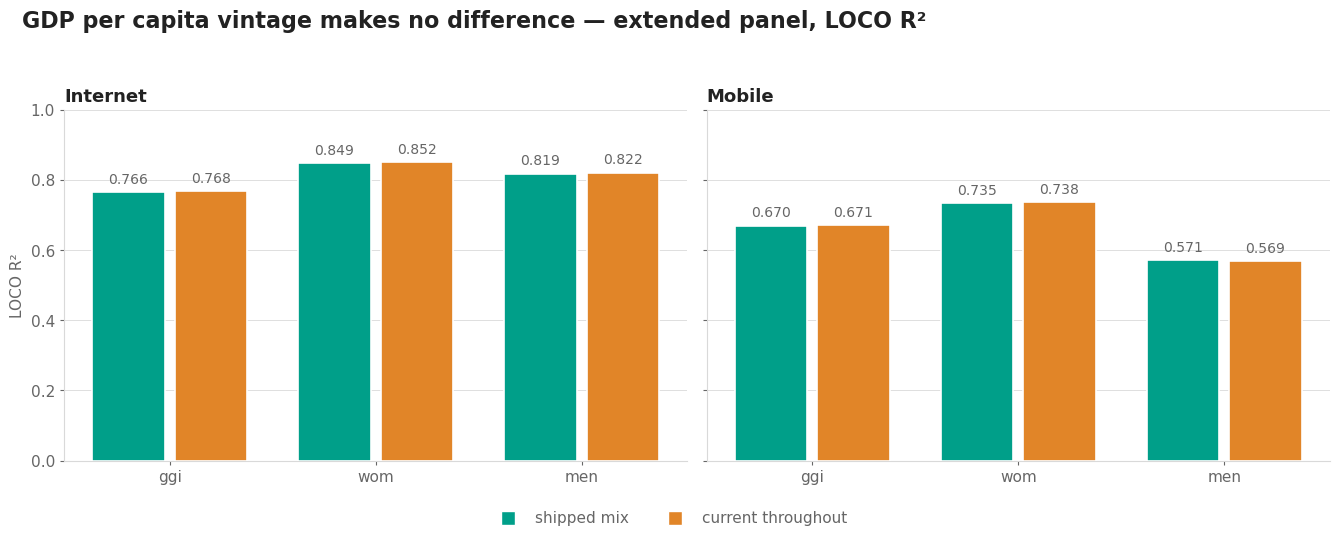

median |Δ log gdp_pcap| between vintages : 0.0076
median |β| on gdp_pcap                   : 0.0469
implied move in a fitted outcome         : 0.000357
model LOCO MAE, for scale                : 0.084


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5), sharey=True)

COLOUR = {'shipped mix': plot.PALETTE[0], 'current throughout': plot.PALETTE[1]}
ORDER = ['shipped mix', 'current throughout']

for ax, indicator in zip(axes, CFG['indicators']):
    block = vintages[(vintages['indicator'] == indicator) & (vintages['panel'] == 'extended')]
    cats = CFG['outcome_vars']
    values = {v: [block[(block['outcome'] == o) & (block['vintage'] == v)]['loco_r2'].iloc[0]
                  for o in cats] for v in ORDER}
    plot.grouped_bars(ax, cats, ORDER, values, colours=COLOUR, fmt='{:.3f}')
    plot.tidy(ax, title=indicator.capitalize(), grid='y')
    ax.set_ylim(0, 1)

axes[0].set_ylabel('LOCO R²', fontsize=plot.STYLE['tick_fs'], color=plot.MUTED)
plot.legend(fig, [plot.swatch(COLOUR[v], v) for v in ORDER], y=-0.08)
plot.suptitle(fig, 'GDP per capita vintage makes no difference — extended panel, LOCO R²')
fig.tight_layout(rect=(0, 0, 1, 0.93))
plot.save(fig, NOTEBOOK, '3_gdp_vintage')
plt.show()

# why it cannot matter: the revision is small, and the coefficient it passes through is smaller
beta = vintages[vintages['vintage'] == 'shipped mix']['beta_gdp_pcap'].abs().median()
med = np.log1p(seam['rel'].median())
print(f'median |Δ log gdp_pcap| between vintages : {med:.4f}')
print(f'median |β| on gdp_pcap                   : {beta:.4f}')
print(f'implied move in a fitted outcome         : {beta * med:.6f}')
print(f'model LOCO MAE, for scale                : {vintages["loco_mae"].median():.3f}')


### What the vintage test says

**Nothing measurable changes.** Across all twelve comparisons the LOCO R² moves by at most **0.005**,
and the sample size is identical in every arm — re-sourcing loses no rows, so this is a clean
like-for-like swap rather than a different panel.

| | internet ggi | internet wom | internet men | mobile ggi | mobile wom | mobile men |
| --- | --- | --- | --- | --- | --- | --- |
| extended, shipped mix | 0.766 | 0.849 | 0.819 | 0.670 | 0.735 | 0.571 |
| extended, current throughout | 0.768 | 0.852 | 0.822 | 0.671 | 0.738 | 0.569 |

**And the reason is arithmetic, not luck.** The vintage seam is real and sizeable *as a revision to
GDP*: below 2022 only 1–10% of cells are identical between the shipped file and today's API, with a
median revision of 0.8% and up to 2.1% in 2020–2022. But `gdp_pcap` enters logged, so a 0.8%
revision is a change of 0.008 in the regressor, and the median absolute coefficient it passes
through is 0.047 across the six targets (0.006 for the internet GGI alone). The implied move in a
fitted outcome is **~0.0004** — more than two orders of magnitude below the model's own MAE of
0.084.

So the honest conclusion is not "the vintage mix is fine". It is:

> `gdp_pcap` carries so little weight in this specification that its vintage cannot matter. The
> mixed-vintage seam is a genuine data-quality defect, and it is invisible here because the
> predictor it affects is nearly inert.

That is worth knowing for two reasons. It closes the vintage question for this spec — no need to
rebuild history to fix it. And it re-raises the prior one: a regressor whose coefficient is 0.006
and whose 200-fold mis-scaling changed LOCO R² by only 0.007 (§1) is a term the specification may not
need at all. `14_specification_stability.ipynb` sweeps exactly that question.

**What this does not test.** `hdi` and `gdi` have the same 2022 seam and are *not* re-sourced here —
HDR revises its whole back-series each edition and the API serves only the current one, so a
single-vintage HDI means rebuilding history (`06_offline_predictors_build.py`, D40). Those two carry
far more weight than `gdp_pcap`, so their seam is the one that could actually move a result. It
remains untested.


## 6. Write the tables

In [12]:
stamp = f'{datetime.now():%Y%m%d}'
for name, frame in [('extended_panel_performance', perf),
                    ('extended_panel_coefficients', coefs),
                    ('extended_panel_added_survey_predictions', preds_long),
                    ('extended_panel_gdp_vintage', vintages)]:
    path = params.table_dir(NOTEBOOK) / f'{name}_{stamp}.csv'
    frame.to_csv(path, index=False)
    print(f'{path.name:48s} {len(frame):5d} rows')

extended_panel_performance_20260821.csv             12 rows
extended_panel_coefficients_20260821.csv            96 rows
extended_panel_added_survey_predictions_20260821.csv   927 rows
extended_panel_gdp_vintage_20260821.csv             24 rows


## Notes

- **Exploration, not a proposal.** Adopting the extended panel would mean refitting the production
  models, which re-bases every published prediction. Nothing here does that.
- **The `np.log` on `gdp_pcap` is load-bearing.** `offline_predictors.csv` stores raw current US$;
  the fitted panel stores logs (`scripts/predictors.py:194`). Without the log the added rows arrive
  ~200× the existing ones and the `gdp_pcap` coefficient collapses to zero — the term is silently
  dropped and the notebook reports a −100% coefficient change as if it were a finding. The scale
  assertion in `extend()` exists so that failure cannot recur silently.
- The added rows carry **2023** development indicators for 15 of 17 surveys, 2022 for the other two.
  Any deterioration they show may still be that staleness rather than the surveys themselves, but
  the effect is far smaller than it was before the predictors were extended.
- **The vintage seam is real but inert for `gdp_pcap`** (§5): below 2022 only 1–10% of values match
  today's API, yet re-sourcing the whole column moves LOCO R² by at most 0.005. `hdi` and `gdi` have
  the same seam and carry far more weight; their vintage remains untested.
- **§4's MAEs are not `03`'s.** `03` scores the published series; §4 scores a refit on
  predictors assembled in §1, because both sides of its comparison have to be refits.
  Internet women: 0.140 there, 0.147 here, 0.152 country-held-out. Same 17 rows, same
  ground truth to 0.0 — see the reconciliation under §4.
- `02_model_performance.ipynb` is the production audit; `03_unseen_survey_validation.ipynb` scores
  the same surveys as **held-out**, which is the complementary question to this one.
